# Buscando la gira con algoritmos genéticos

Inteligencia Artificial - Facundo A. Lucianna - CEIA - FIUBA

En la notebook anterior vimos que Local Beam, al buscar con varias giras a la vez, pierde enseguida la diversidad: todas las giras del haz terminan siendo variaciones de una sola. Ahora vamos a probar con los **algoritmos genéticos**, que también trabajan con un conjunto de giras, pero las giras nuevas no salen de modificar una sola gira, sino de **combinar dos**.

La idea viene de la evolución de las especies. Tenemos una **población** de giras. En cada **generación**, elegimos a las mejores como **padres**, las combinamos para formar **hijos** que heredan características de los dos, y de vez en cuando les aplicamos una **mutación**. Las giras más cortas tienen más chances de reproducirse, así que, generación tras generación, la población debería ir mejorando.

Mientras tanto, el manager ya tiene el teléfono de la imprenta en la mano. Empecemos, como siempre, con la Gira Federal:

In [1]:
import random

import matplotlib.pyplot as plt
import numpy as np

import gira

random.seed(42)

capitals = gira.load_cities("capitales")
distances = gira.distance_matrix(capitals)

---

## Las definiciones

Para usar un algoritmo genético hay que definir varias cosas, y ninguna es única: todas son decisiones de diseño que dependen del problema.

### Cromosoma

El **cromosoma** es la forma en que codificamos una solución para poder combinarla y mutarla. En nuestro caso, el cromosoma es directamente la gira: la lista de ciudades en el orden en que se visitan. Cada **gen** es una ciudad.

In [2]:
tour = gira.init_state(capitals)
names = capitals["nombre"].tolist()

print("Cromosoma:", tour)
print("Primeros genes:", [names[city] for city in tour[:4]])

Cromosoma: [5, 17, 16, 2, 15, 6, 14, 18, 13, 23, 7, 10, 1, 20, 12, 11, 22, 4, 19, 8, 9, 0, 3, 21, 24]
Primeros genes: ['Buenos Aires', 'Río Gallegos', 'Salta', 'La Plata']


### Población

La **población** es un conjunto de giras. La población inicial la armamos con giras al azar:

In [3]:
population = [gira.init_state(capitals) for _ in range(6)]

for tour in population:
    print(gira.format_km(gira.cost_function(tour, distances)))

32.004 km
28.704 km
31.591 km
25.164 km
26.716 km
28.642 km


### Idoneidad

La **función de idoneidad** (*fitness*) mide qué tan buena es una solución. Usamos la misma función de costo de siempre, los km de la gira, con la diferencia de que acá cuanto menor es el valor, más idónea es la gira.

### Selección

Para elegir a los padres usamos **selección por torneo**: tomamos unas pocas giras al azar de la población (en nuestro caso, 3) y la de menor costo gana. Las giras cortas tienen más chances de ganar, pero cualquier gira puede ser elegida si le tocan rivales peores. Esto ayuda a mantener la diversidad de la población.

In [4]:
TOURNAMENT_SIZE = 3


def tournament_selection(population, costs):
    """
    Elige una gira de la población por torneo: toma TOURNAMENT_SIZE giras al azar y
    devuelve la de menor costo.

    Args:
        population (list): Lista de giras.
        costs (list): Costo de cada gira de la población.

    Returns:
        list: La gira ganadora del torneo.
    """
    competitors = random.sample(range(len(population)), TOURNAMENT_SIZE)
    winner = min(competitors, key=lambda index: costs[index])
    return population[winner]

In [5]:
costs = [gira.cost_function(tour, distances) for tour in population]
winner = tournament_selection(population, costs)

print("Ganador del torneo:", gira.format_km(gira.cost_function(winner, distances)))

Ganador del torneo: 28.642 km


### Reproducción

La **reproducción** es la operación que combina dos padres para formar un hijo. La forma más simple es elegir un punto de corte al azar y pegar el principio de un padre con el final del otro. Veamos qué pasa si lo hacemos con dos giras, usando letras en lugar de ciudades para que se vea mejor:

In [6]:
parent_a = ["BA", "A", "B", "C", "D", "E", "F", "Marambio"]
parent_b = ["BA", "E", "C", "F", "A", "D", "B", "Marambio"]

cut = 4
child = parent_a[:cut] + parent_b[cut:]

print("Padre A:", parent_a)
print("Padre B:", parent_b)
print("Hijo:   ", child)

Padre A: ['BA', 'A', 'B', 'C', 'D', 'E', 'F', 'Marambio']
Padre B: ['BA', 'E', 'C', 'F', 'A', 'D', 'B', 'Marambio']
Hijo:    ['BA', 'A', 'B', 'C', 'A', 'D', 'B', 'Marambio']


El hijo no es una gira válida: pasa dos veces por A y por B, y nunca pasa por E ni por F. Al cortar y pegar, no hay nada que garantice que cada ciudad aparezca una sola vez. Es el mismo problema que vimos en la primera notebook al definir el estado: la reproducción tiene que respetar la representación, igual que los vecinos.

Por eso usamos la **reproducción por orden** (*order crossover* u OX), pensado para cromosomas que son permutaciones:

1. Elegimos un tramo al azar del padre A y lo copiamos al hijo, en las mismas posiciones.
2. Completamos los lugares que quedan libres con las ciudades que faltan, en el orden en que aparecen en el padre B.

Así, el hijo hereda un tramo del padre A y el orden relativo del resto de las ciudades del padre B, y cada ciudad aparece una única vez. Como siempre, la primera y la última posición no se tocan.

In [7]:
def order_crossover(parent_a, parent_b):
    """
    Reproducción por orden (OX): copia un tramo al azar del padre A, en las mismas
    posiciones, y completa el resto con las ciudades que faltan en el orden en que
    aparecen en el padre B. El primer y el último lugar de la gira no se tocan.

    Args:
        parent_a (list): Gira del padre A.
        parent_b (list): Gira del padre B.

    Returns:
        list: La gira hija.
    """
    i, j = gira.random_move(len(parent_a))
    segment = parent_a[i : j + 1]

    # Las ciudades del padre B que no están en el tramo, en el orden de B
    in_segment = set(segment)
    rest = [city for city in parent_b[1:-1] if city not in in_segment]

    # Las primeras i - 1 ciudades de rest van antes del tramo y las demás, después
    middle = rest[: i - 1] + segment + rest[i - 1 :]
    return [parent_a[0], *middle, parent_a[-1]]

Para elegir el tramo reutilizamos `random_move()`, que ya nos da dos posiciones al azar sin tocar los extremos. Probemos con las mismas giras de letras:

In [8]:
for _ in range(3):
    print("Hijo:", order_crossover(parent_a, parent_b))

Hijo: ['BA', 'E', 'B', 'C', 'F', 'A', 'D', 'Marambio']
Hijo: ['BA', 'F', 'B', 'C', 'D', 'E', 'A', 'Marambio']
Hijo: ['BA', 'A', 'B', 'C', 'D', 'E', 'F', 'Marambio']


### Mutación

La **mutación** introduce cambios al azar en los hijos, para que aparezcan características que no estaban en ninguno de los padres. Para nuestra gira ya tenemos una mutación natural: aplicar un movimiento 2-opt al azar, es decir, movernos a un vecino al azar con `random_neib_state()`. Cada hijo muta con una cierta probabilidad.

### Elitismo

Por último, para no perder las mejores giras encontradas, las 2 mejores de cada generación pasan directamente a la siguiente, sin reproducirse ni mutar. Esto se conoce como **elitismo**.

---

## Implementando el algoritmo genético

Con todas las piezas definidas, armamos el algoritmo. Veamos la implementación, prestando atención a los comentarios. El parámetro `improvement_tries` lo vamos a usar más adelante; por ahora lo dejamos en 0.

In [9]:
ELITE_SIZE = 2


def improve_tour(tour, distances, tries):
    """
    Mejora una gira probando movimientos 2-opt al azar y aplicando solo los que
    reducen el costo.

    Args:
        tour (list): La gira.
        distances (np.ndarray): Matriz de distancias entre ciudades.
        tries (int): Cantidad de movimientos que se prueban.

    Returns:
        list: La gira mejorada.
    """
    for _ in range(tries):
        i, j = gira.random_move(len(tour))
        if gira.delta_cost(tour, i, j, distances) < 0:
            tour = gira.two_opt(tour, i, j)
    return tour


def genetic_algorithm(
    initial_population,
    distances,
    max_generations=1_000,
    mutation_probability=0.5,
    improvement_tries=0,
):
    """
    Busca la mejor gira con un algoritmo genético. En cada generación, las
    ELITE_SIZE mejores giras pasan directo a la siguiente, y el resto de la nueva
    población se forma con hijos de dos padres elegidos por torneo, combinados con
    la reproducción por orden y mutados con un movimiento 2-opt al azar.

    Args:
        initial_population (list): Las giras de la población inicial.
        distances (np.ndarray): Matriz de distancias entre ciudades.
        max_generations (int, opcional): Cantidad de generaciones. Por defecto 1.000.
        mutation_probability (float, opcional): Probabilidad de que un hijo mute.
                                                Por defecto 0,5.
        improvement_tries (int, opcional): Si es mayor que 0, cada gira nueva se
                                           mejora con improve_tour(), probando esa
                                           cantidad de movimientos 2-opt (algoritmo
                                           memético). Por defecto 0.

    Returns:
        tuple: (la mejor gira encontrada, lista con el costo de la mejor gira de
               cada generación)
    """
    population_size = len(initial_population)
    population = [
        improve_tour(tour, distances, improvement_tries) for tour in initial_population
    ]
    costs = [gira.cost_function(tour, distances) for tour in population]
    history = [min(costs)]

    for _ in range(max_generations):
        # Elitismo: las mejores giras pasan directo a la nueva generación
        ranking = sorted(range(population_size), key=lambda index: costs[index])
        new_population = [population[index] for index in ranking[:ELITE_SIZE]]

        while len(new_population) < population_size:
            # Selección: dos padres elegidos por torneo
            parent_a = tournament_selection(population, costs)
            parent_b = tournament_selection(population, costs)

            # Reproducción y mutación
            child = order_crossover(parent_a, parent_b)
            if random.random() < mutation_probability:
                child = gira.random_neib_state(child)

            child = improve_tour(child, distances, improvement_tries)
            new_population.append(child)

        population = new_population
        costs = [gira.cost_function(tour, distances) for tour in population]
        history.append(min(costs))

    best = int(np.argmin(costs))
    return population[best], history

Probemos con una población de 100 giras al azar y 300 generaciones:

In [10]:
initial_population = [gira.init_state(capitals) for _ in range(100)]
genetic_tour, history = genetic_algorithm(
    initial_population, distances, max_generations=300
)

print("Mejor gira de la población inicial:", gira.format_km(history[0]))
print("Mejor gira de la última generación:", gira.format_km(history[-1]))

Mejor gira de la población inicial: 23.739 km
Mejor gira de la última generación: 8.410 km


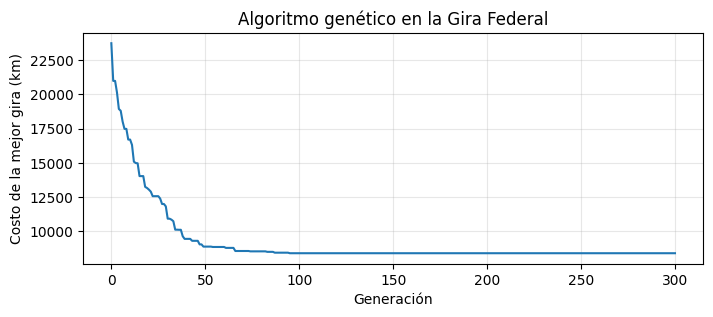

In [11]:
plt.figure(figsize=(8, 3))
plt.plot(history)
plt.xlabel("Generación")
plt.ylabel("Costo de la mejor gira (km)")
plt.title("Algoritmo genético en la Gira Federal")
plt.grid(alpha=0.3)
plt.show()

En las primeras generaciones el costo baja muy rápido: combinar giras al azar y quedarse con las mejores alcanza para eliminar los peores tramos. Después la mejora se vuelve más lenta, a medida que la población se parece cada vez más a la mejor gira.

> 🗺️ **Nota**: La celda de abajo genera un mapa interactivo, donde se puede hacer zoom y ver el nombre y la fecha de cada ciudad al pasar el mouse. La dejamos sin ejecutar para que la notebook sea liviana. Si querés verlo, ejecutala. Debajo está la versión estática del mismo mapa.

In [ ]:
gira.plot_tour(
    capitals, genetic_tour, distances, title="Algoritmo genético", interactive=True
)

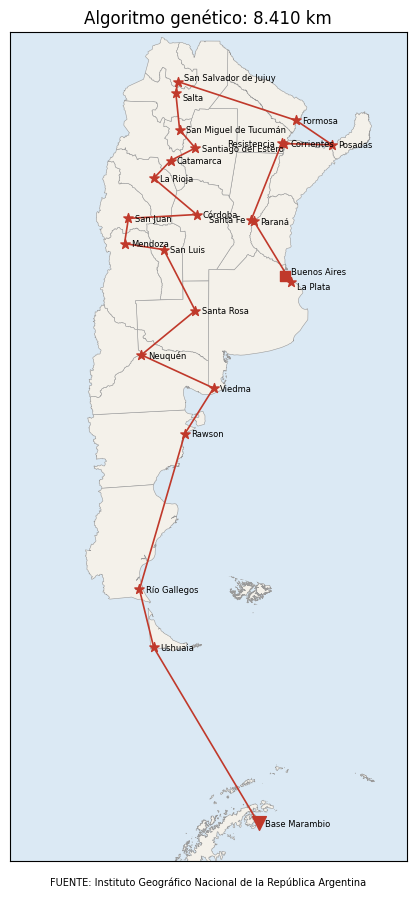

In [12]:
gira.plot_tour(capitals, genetic_tour, distances, title="Algoritmo genético")

---

## La Gira Pueblo por Pueblo

Vamos con la gira grande. Usamos una población de 100 giras y 3.000 generaciones, y repetimos 5 veces:

In [13]:
cities = gira.load_cities("pueblo_por_pueblo")
city_distances = gira.distance_matrix(cities)

genetic_results = []
for _ in range(5):
    initial_population = [gira.init_state(cities) for _ in range(100)]
    genetic_tour, _ = genetic_algorithm(
        initial_population, city_distances, max_generations=3_000
    )
    genetic_results.append(
        (gira.cost_function(genetic_tour, city_distances), genetic_tour)
    )

genetic_results.sort(key=lambda result: result[0])
genetic_costs = [cost for cost, _ in genetic_results]
print(f"Mejor: {gira.format_km(min(genetic_costs))}")
print(f"Promedio: {gira.format_km(np.mean(genetic_costs))}")
print(f"Peor: {gira.format_km(max(genetic_costs))}")

Mejor: 14.645 km
Promedio: 15.247 km
Peor: 15.675 km


El resultado es decepcionante: con 111 ciudades, el algoritmo genético es peor que ejecutar gradiente descendente 10 veces, que en la notebook anterior dio alrededor de 14.600 km, y está lejos de Simulated Annealing. Veamos su mejor gira:

> 🗺️ **Nota**: La celda de abajo genera un mapa interactivo, donde se puede hacer zoom y ver el nombre y la fecha de cada ciudad al pasar el mouse. La dejamos sin ejecutar para que la notebook sea liviana. Si querés verlo, ejecutala. Debajo está la versión estática del mismo mapa.

In [ ]:
gira.plot_tour(
    cities,
    genetic_results[0][1],
    city_distances,
    title="Algoritmo genético",
    interactive=True,
)

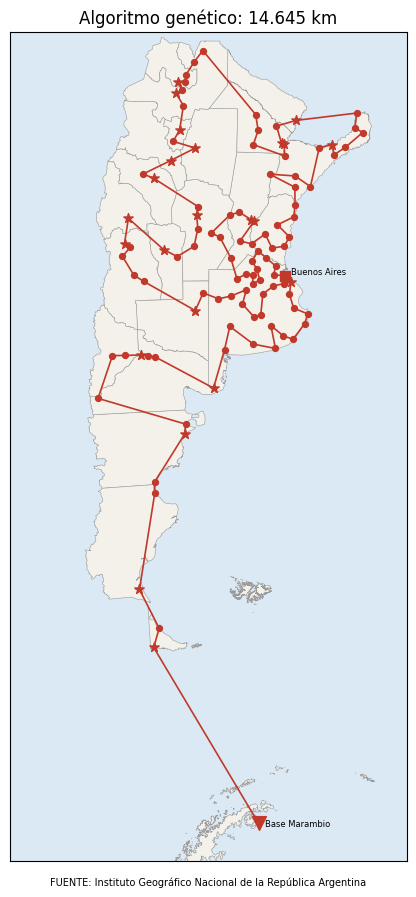

In [14]:
gira.plot_tour(
    cities, genetic_results[0][1], city_distances, title="Algoritmo genético"
)

¿Será que al algoritmo le faltó terminar de ajustar la gira? Contemos cuántos movimientos 2-opt todavía la mejoran, y veamos qué pasa si le aplicamos gradiente descendente:

In [15]:
from search_methods import gradient_descent

best_genetic = genetic_results[0][1]
improving_moves = [
    (i, j)
    for i, j in gira.obtain_moves(len(best_genetic))
    if gira.delta_cost(best_genetic, i, j, city_distances) < 0
]
polished_tour, _ = gradient_descent(best_genetic, city_distances)
polished_km = gira.cost_function(polished_tour, city_distances)

print(f"Movimientos 2-opt que mejoran la gira: {len(improving_moves)}")
print("Después de gradiente descendente:", gira.format_km(polished_km))

Movimientos 2-opt que mejoran la gira: 0
Después de gradiente descendente: 14.645 km


Ningún movimiento 2-opt mejora la gira: después de 3.000 generaciones, la mutación ya se encargó de los ajustes finos, y la gira es un mínimo local, igual que las que encuentra gradiente descendente. El problema no es que le falte ajustar, sino que quedó atrapada en un mínimo local bastante peor que los que encuentran los otros algoritmos.

---

## ¿Por qué le cuesta tanto?

La idea de la reproducción es que el hijo herede lo bueno de cada padre. Pero, ¿qué es lo bueno de una gira? No es la posición de cada ciudad, sino los **tramos**: qué ciudad va al lado de cuál. La reproducción por orden copia un tramo del padre A, pero el resto de las ciudades las reacomoda según el orden del padre B, y en ese reacomodo aparecen muchos tramos nuevos que no estaban en ninguno de los padres.

Veámoslo con dos giras buenas, que obtenemos con gradiente descendente. Las reproducimos 100 veces entre sí y miramos el costo de los hijos:

In [16]:
parent_a, _ = gradient_descent(gira.init_state(cities), city_distances)
parent_b, _ = gradient_descent(gira.init_state(cities), city_distances)

children_costs = [
    gira.cost_function(order_crossover(parent_a, parent_b), city_distances)
    for _ in range(100)
]

print("Padre A:", gira.format_km(gira.cost_function(parent_a, city_distances)))
print("Padre B:", gira.format_km(gira.cost_function(parent_b, city_distances)))
print("Costo promedio de los hijos:", gira.format_km(np.mean(children_costs)))
print("Mejor hijo:", gira.format_km(min(children_costs)))

Padre A: 15.448 km
Padre B: 14.848 km
Costo promedio de los hijos: 17.226 km
Mejor hijo: 15.416 km


Los hijos de dos giras buenas son, en promedio, bastante peores que sus padres, y ninguno de los 100 mejora al mejor de ellos. La reproducción rompe buena parte de lo que tenían de bueno, y el algoritmo pasa la mayor parte del tiempo reparando lo que la reproducción rompió.

---

## Algoritmo memético: genético + búsqueda local

Una forma muy usada de mejorar a los algoritmos genéticos es combinarlos con búsqueda local: después de crear cada hijo, lo mejoramos un poco antes de agregarlo a la población. Esto se conoce como **algoritmo memético**.

Para eso está el parámetro `improvement_tries` de nuestra implementación: cada gira nueva prueba esa cantidad de movimientos 2-opt al azar y aplica los que la mejoran, con la función `improve_tour()`. Es como un gradiente descendente estocástico corto, que repara los tramos que rompió la reproducción.

Como cada hijo ahora es más caro de crear, usamos una población más chica, de 50 giras, y 300 generaciones:

In [17]:
memetic_results = []
for _ in range(5):
    initial_population = [gira.init_state(cities) for _ in range(50)]
    memetic_tour, _ = genetic_algorithm(
        initial_population,
        city_distances,
        max_generations=300,
        improvement_tries=1_000,
    )
    memetic_results.append(
        (gira.cost_function(memetic_tour, city_distances), memetic_tour)
    )

memetic_results.sort(key=lambda result: result[0])
memetic_costs = [cost for cost, _ in memetic_results]
print(f"Mejor: {gira.format_km(min(memetic_costs))}")
print(f"Promedio: {gira.format_km(np.mean(memetic_costs))}")
print(f"Peor: {gira.format_km(max(memetic_costs))}")

Mejor: 14.292 km
Promedio: 14.437 km
Peor: 14.562 km


El algoritmo memético mejora mucho al genético puro, y también a las 10 ejecuciones de gradiente descendente de la notebook anterior. Pero cada ejecución tarda bastante más que una de Simulated Annealing, y en promedio sigue quedando por detrás de él, que en la notebook 3 promedió 14.256 km.

Comparemos la mejor gira de cada versión:

> 🗺️ **Nota**: La celda de abajo genera un mapa interactivo, donde se puede hacer zoom y ver el nombre y la fecha de cada ciudad al pasar el mouse. La dejamos sin ejecutar para que la notebook sea liviana. Si querés verlo, ejecutala. Debajo está la versión estática del mismo mapa.

In [ ]:
gira.plot_tours(
    cities,
    {"Genético": genetic_results[0][1], "Memético": memetic_results[0][1]},
    city_distances,
    interactive=True,
)

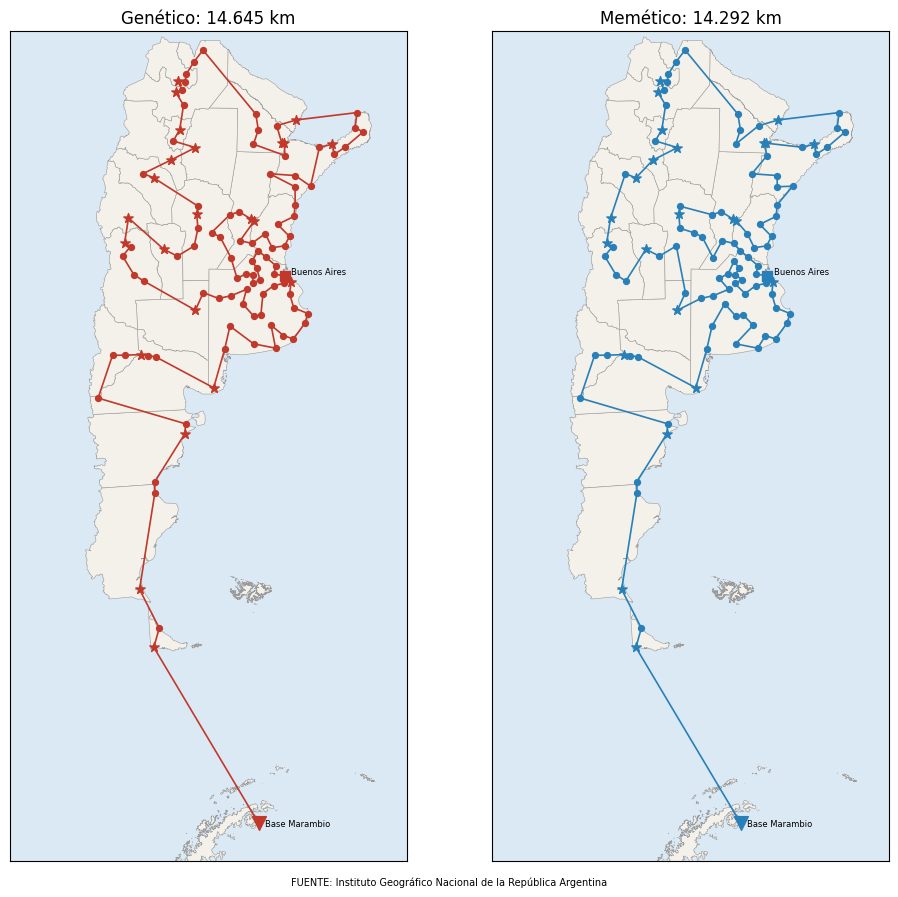

In [18]:
gira.plot_tours(
    cities,
    {"Genético": genetic_results[0][1], "Memético": memetic_results[0][1]},
    city_distances,
)

---

## ¿Imprimimos un nuevo cartel?

Comparemos con la gira del cartel, la que encontró Simulated Annealing: 14.123 km.

In [19]:
POSTER_KM = 14_123

best_cost = memetic_results[0][0]
print("Mejor gira del algoritmo memético:", gira.format_km(best_cost))
print("Gira del cartel:", gira.format_km(POSTER_KM))
print(f"Diferencia: {gira.format_km(best_cost - POSTER_KM)} más")

Mejor gira del algoritmo memético: 14.292 km
Gira del cartel: 14.123 km
Diferencia: 169 km más


Tampoco esta vez hay que imprimir: la gira del cartel sigue siendo la mejor que encontramos. El manager cuelga el teléfono de la imprenta, un poco decepcionado, porque ya se había encariñado con la idea de un tercer cartel.

En la próxima notebook ponemos a todos los algoritmos lado a lado para sacar conclusiones.

> 🧠 **Nota**: Las funciones `tournament_selection()`, `order_crossover()`, `improve_tour()` y `genetic_algorithm()` también están en el archivo `search_methods.py`.